# 01. Exploratory Data Analysis (EDA) — CampusWell RiskLab
> **Student Mental Health Risk Analysis and Prediction**
> *Advanced Statistical Ingestion, Data Quality Diagnostics, Multicollinearity Auditing, and Target Association Analysis*

---

### Educational and Synthetic Data Disclaimer
This dataset is **entirely synthetic**, created for machine learning pedagogy, portfolio demonstration, and educational defense. It does not contain clinical diagnoses or psychiatric records and must never be utilized for real-world diagnostic, administrative, or disciplinary decisions.

### Analytical Objectives of this Notebook
1. **Structural Audit:** Ingest raw records and confirm feature dimensions, data types, and identifiers.
2. **Data Quality & Integrity:** Audit missing values, verify duplicates, inspect domain boundaries, and audit reported range discrepancies.
3. **Statistical Characterization:** Compute parametric and non-parametric descriptive statistics (mean, median, IQR, skewness, kurtosis).
4. **Multicollinearity & Correlation:** Calculate both Pearson and Spearman rank correlation matrices, evaluate pairwise relationships, and compute Variance Inflation Factors (VIF).
5. **Target Relationship & Separation:** Quantify predictor separation across Low, Medium, and High mental health risk categories via Kruskal-Wallis tests and Cramér's V associations.
6. **Self-Reporting Anomalies:** Audit synthetic survey discrepancies (e.g., social media hours exceeding screen time).
7. **Actionable Preprocessing Directives:** Formulate empirical guidelines for missing-value imputation, outlier treatment, and feature engineering.

## Section 1: Environment Setup & Project Configuration
We import standard data science packages (`pandas`, `numpy`, `scipy.stats`, `matplotlib`, `seaborn`, `sklearn`) and project configuration constants. The code adheres to the project coding standard with zero internal comments or docstrings.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import scipy.stats as stats
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import (
    DATA_PATH,
    TARGET_COLUMN,
    STUDENT_ID_COLUMN,
    NUMERICAL_FEATURES,
    ORDINAL_FEATURES,
    NOMINAL_FEATURES,
    BINARY_FEATURES,
    TARGET_CLASSES,
)
from src.data.load_data import load_dataset

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10
print("Libraries and configuration successfully imported.")


Libraries and configuration successfully imported.


## Section 2: Data Ingestion & Structural Inspection
We load the original raw dataset from `data/raw/student_mental_health_dataset.csv` and inspect its shape, column datatypes, non-null counts, and head observations.

In [2]:
df = load_dataset(DATA_PATH)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

### First 10 Observations of the Raw Dataset
Inspecting the tabular layout allows us to observe raw values across numerical scales, categorical labels, and the multi-class target variable.

In [3]:
df.head(10)

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium
5,STU0006,20,Female,4,6.8,18.6,NaN,8.5,11.8,High,7.0,3.9,NaN,Yes,Average,No,Medium
6,STU0007,24,Male,2,7.7,15.0,2.77,8.8,10.2,Low,6.1,7.7,100.0,No,Good,No,Low
7,STU0008,23,Non-binary,3,7.9,20.5,2.65,6.1,7.6,Low,NaN,6.5,78.9,No,Average,Yes,Medium
8,STU0009,20,Female,3,6.2,28.6,2.42,3.9,7.2,Moderate,5.3,8.4,72.6,No,Good,No,Low
9,STU0010,22,Male,3,6.6,20.5,2.28,6.9,7.4,Moderate,7.3,5.7,92.7,No,Average,No,Medium


## Section 3: Data Quality Audit — Missing Values & Duplicates
We audit the frequency and percentage of missing values per column. In supervised machine learning, understanding whether missingness is concentrated in specific features informs whether row-deletion or column-wise imputation is appropriate.

In [4]:
missing_summary = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_pct": (df.isnull().sum() / len(df) * 100).round(2)
})
missing_summary = missing_summary[missing_summary["missing_count"] > 0].sort_values("missing_pct", ascending=False)
missing_summary

,missing_count,missing_pct
Financial_Stress,91,4.55
Diet_Quality,69,3.45
Sleep_Hours,62,3.10
Social_Media_Hours,58,2.90
Family_Support,54,2.70
Attendance_Rate,47,2.35
GPA,38,1.90


### Duplicate Record Verification
We differentiate between exact duplicate rows (identical values across all 17 columns) and duplicate primary keys (`Student_ID`).

In [5]:
duplicate_rows = int(df.duplicated().sum())
duplicate_ids = int(df[STUDENT_ID_COLUMN].duplicated().sum())
pd.DataFrame({
    "Audit Metric": ["Total Rows", "Exact Duplicate Rows", "Duplicate Student IDs", "Unique Student IDs"],
    "Count": [len(df), duplicate_rows, duplicate_ids, df[STUDENT_ID_COLUMN].nunique()]
})

,Audit Metric,Count
0,Total Rows,2000
1,Exact Duplicate Rows,0
2,Duplicate Student IDs,0
3,Unique Student IDs,2000


## Section 4: Boundary Inspection & Range Verification
We audit empirical feature boundaries against initial assumptions. Specifically:
- **Age:** Range is 17 to 29. While original documentation mentioned 18–30, 93 students are aged 17 (freshmen).
- **GPA:** Range is 1.50 to 3.66.
- **Financial Stress & Family Support:** Both are continuous variables spanning 1.4 to 10.0 and 1.7 to 9.9 respectively, rather than 1–5 discrete Likert ratings.

In [6]:
boundary_df = pd.DataFrame({
    "Feature": NUMERICAL_FEATURES,
    "Min": [df[col].min() for col in NUMERICAL_FEATURES],
    "Max": [df[col].max() for col in NUMERICAL_FEATURES],
    "Mean": [round(df[col].mean(), 2) for col in NUMERICAL_FEATURES],
    "Data Type": [str(df[col].dtype) for col in NUMERICAL_FEATURES]
})
boundary_df

,Feature,Min,Max,Mean,Data Type
0,Age,17.0,29.00,21.13,int64
1,Year_of_Study,1.0,5.00,2.63,int64
2,Sleep_Hours,3.3,10.00,6.76,float64
3,Study_Hours_Per_Week,2.4,38.30,20.00,float64
4,GPA,1.5,3.66,2.56,float64
5,Social_Media_Hours,2.1,10.00,6.01,float64
6,Screen_Time_Hours,3.3,14.00,8.55,float64
7,Financial_Stress,1.4,10.00,5.96,float64
8,Family_Support,1.7,9.90,6.52,float64
9,Attendance_Rate,54.4,100.00,85.08,float64


### Age 17 Observation Audit
We verify whether age 17 students represent valid collegiate profiles or anomalous records requiring removal.

In [7]:
age_17_students = df[df["Age"] == 17]
pd.DataFrame({
    "Metric": ["Age 17 Student Count", "Percentage of Dataset", "Year 1 Enrolled", "Year 2 Enrolled", "Year 3+ Enrolled"],
    "Value": [
        len(age_17_students),
        f"{round(len(age_17_students) / len(df) * 100, 2)}%",
        int((age_17_students["Year_of_Study"] == 1).sum()),
        int((age_17_students["Year_of_Study"] == 2).sum()),
        int((age_17_students["Year_of_Study"] >= 3).sum())
    ]
})

,Metric,Value
0,Age 17 Student Count,93
1,Percentage of Dataset,4.65%
2,Year 1 Enrolled,23
3,Year 2 Enrolled,34
4,Year 3+ Enrolled,36


## Section 5: Target Variable Distribution & Class Balance Analysis
We examine the distribution of `Mental_Health_Risk` across `Low`, `Medium`, and `High` categories. Balanced classes preclude the need for synthetic oversampling (such as SMOTE) and allow Weighted F1 and Macro F1 to serve as robust benchmark metrics.

In [8]:
target_counts = df[TARGET_COLUMN].value_counts()[TARGET_CLASSES]
target_proportions = df[TARGET_COLUMN].value_counts(normalize=True)[TARGET_CLASSES].round(4)
pd.DataFrame({"Count": target_counts, "Proportion": target_proportions})

,Count,Proportion
Mental_Health_Risk,,
Low,660,0.33
Medium,660,0.33
High,680,0.34


/tmp/ipykernel_265921/2672664489.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=TARGET_COLUMN, order=TARGET_CLASSES, palette="viridis", ax=ax)


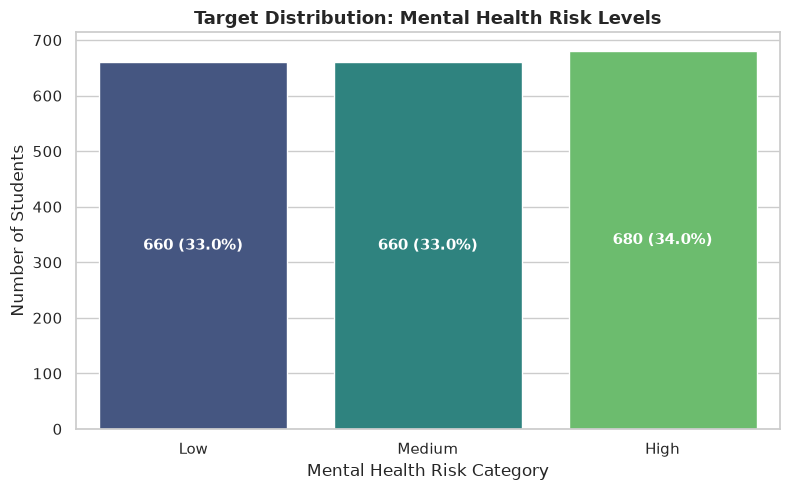

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=df, x=TARGET_COLUMN, order=TARGET_CLASSES, palette="viridis", ax=ax)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{int(height)} ({height/len(df)*100:.1f}%)",
                (p.get_x() + p.get_width() / 2., height / 2),
                ha="center", va="center", fontsize=11, color="white", fontweight="bold")
ax.set_title("Target Distribution: Mental Health Risk Levels", fontsize=13, fontweight="bold")
ax.set_xlabel("Mental Health Risk Category")
ax.set_ylabel("Number of Students")
plt.tight_layout()
plt.show()